In [1]:
from momentum import momentum_strategy
from backtester import run_backtest
import metrics
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
returns = prices.pct_change()
weights = momentum_strategy(prices)
strategy_returns = run_backtest(weights, returns)
spy_returns = returns["SPY"]
start = (weights.shift(1).sum(axis=1) > 0).idxmax()

In [3]:
summary_table = pd.DataFrame({"SPY summary": metrics.summary(spy_returns.loc[start:]), "Strategy summary": metrics.summary(strategy_returns.loc[start:])})
summary_table

,SPY summary,Strategy summary
Annualised Return,0.147070,0.116950
Annualised Volatility,0.170166,0.150804
CAGR,0.141703,0.111303
Sharpe ratio,0.864273,0.775510
Max Drawdown,-0.337173,-0.217139


In [4]:
summary_table = pd.DataFrame({"Strategy 0 bps": metrics.summary(run_backtest(weights, returns, cost=0).loc[start:]), "Strategy 10 bps": metrics.summary(run_backtest(weights, returns, cost=10*0.0001).loc[start:])})
summary_table

,Strategy 0 bps,Strategy 10 bps
Annualised Return,0.116950,0.110582
Annualised Volatility,0.150804,0.150743
CAGR,0.111303,0.104261
Sharpe ratio,0.775510,0.733577
Max Drawdown,-0.217139,-0.221313


yearly turnover ≈ (annualised return at 0 bps − annualised return at 10 bps) ÷ 0.001

yearly turnover ≈ 6.368

In [5]:
held = weights.shift(1).fillna(0)            # what's actually held each day
daily_turnover = held.diff().abs().sum(axis=1)      # total weight change each day

period_turnover = daily_turnover.loc[start:]        # only the backtest period
years = len(period_turnover) / 252
yearly_turnover = period_turnover.sum() / years
print(f"Yearly turnover: {yearly_turnover:.3f}")

Yearly turnover: 6.368


Yearly turnover is 6.4, compared with 4.9 for the 200 day SPY strategy. Since swapping one ETF is a turnover of 2/3, this is roughly 9–10 swaps a year, fewer than one per monthly rebalance and well below the maximum of 24. Turnover is low because consecutive 12 month signals overlap by 11 months, so rankings change slowly and mainly ETFs near the top 3 border get swapped. At 10 bps, costs reduce the annualised return by about 0.64% a year (Sharpe 0.78 → 0.73), a similar drag to the 200-day strategy’s, so costs matter but don’t dominate.

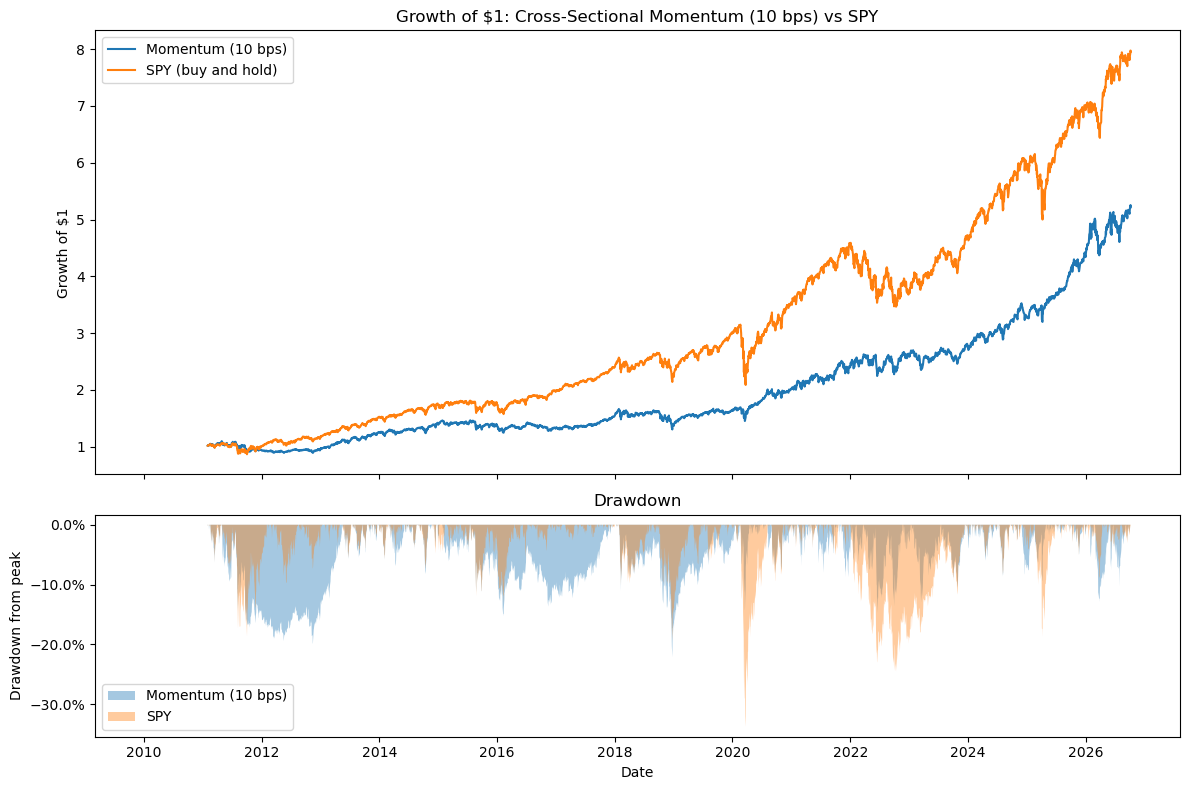

In [6]:

strategy_returns_10bps = run_backtest(weights, returns, cost=0.001)

spy_growth = metrics.growth_of_one(spy_returns.loc[start:])
strategy_growth_10bps = metrics.growth_of_one(strategy_returns.loc[start:])

drawdowns_strategy = metrics.drawdown(strategy_returns_10bps)
drawdowns_spy = metrics.drawdown(spy_returns.loc[start:])

from matplotlib.ticker import PercentFormatter

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})

# Top panel: growth of $1
ax1.plot(strategy_growth_10bps, label="Momentum (10 bps)")
ax1.plot(spy_growth, label="SPY (buy and hold)")
ax1.set_ylabel("Growth of $1")                                    # set_ylabel
ax1.set_title("Growth of $1: Cross-Sectional Momentum (10 bps) vs SPY")  # set_title
ax1.legend()

# Bottom panel: drawdowns
ax2.fill_between(drawdowns_strategy.index, drawdowns_strategy, 0, alpha=0.4, label="Momentum (10 bps)")
ax2.fill_between(drawdowns_spy.index, drawdowns_spy, 0, alpha=0.4, label="SPY")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_title("Drawdown")
ax2.set_ylabel("Drawdown from peak")
ax2.set_xlabel("Date")                                            # x label on the bottom panel
ax2.legend()

fig.tight_layout()                                                # stops titles and labels overlapping
fig.savefig("figures/momentum_12m_top3_10bps_vs_spy.png")         # after BOTH panels are drawn
plt.show()

The strategy’s worst drawdown was smaller (−22% vs −34%), and it held up much better in the sharp sell-offs of 2020 and 2022. However, its drawdowns were longer and came at different times: it fell about 18% in 2011–2012 and took until around 2013 to recover, while SPY recovered quickly. This fits the 12-month lookback: the strategy reacts slowly, so it can be stuck holding last year’s winners when markets turn, and can miss quick rebounds.

In [7]:
strategy_monthly = (1 + strategy_returns_10bps[start:]).resample("ME").prod() - 1
spy_monthly = (1 + spy_returns[start:]).resample('ME').prod() -1


import statsmodels.api as sm


X = sm.add_constant(spy_monthly)       # adds the intercept term
model = sm.OLS(strategy_monthly, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.476
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                     169.9
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           4.73e-28
Time:                        01:45:48   Log-Likelihood:                 417.80
No. Observations:                 189   AIC:                            -831.6
Df Residuals:                     187   BIC:                            -825.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0015      0.002      0.746      0.4

### Summary

I regressed the strategy's monthly returns (after 10 bps costs) on SPY's monthly
returns over the same period, using OLS with a constant:

strategy return = α + β × SPY return + ε

**Beta.** β = 0.63 (t = 13.0, 95% CI 0.53–0.72). A 1% move in SPY is associated with
a 0.63% move in the strategy, so it carries about 63% of SPY's market exposure. The
estimate is precise: the interval is well above 0 and clearly below 1.

**R².** R² = 0.48, so SPY explains about half of the strategy's monthly variation.
The remainder comes from the strategy's own rotation between ETFs.

**Alpha.** The monthly alpha is 0.0015, or about 1.8% a year. This matches the summary
table: market exposure accounts for 0.63 × 14.7% ≈ 9.3% a year, against the 11.1% the
strategy earned, leaving roughly 1.8%. However, the alpha is not statistically
significant (t = 0.75, p = 0.46), and its 95% confidence interval runs from roughly
−2.4% to +6% a year. The data cannot distinguish it from zero.

**Conclusion.** Over this period, the momentum strategy behaves largely like a
lower-risk version of the market: it has clearly less market exposure than SPY, and
any return beyond that exposure is too small and uncertain to be distinguished from
luck. There is no reliable evidence that the momentum rule itself adds return.

### Hypotheses revisited

**1. The strategy behaves much like the market most of the time: partly supported.**
The strategy has a beta of 0.63, so it carries about 63% of SPY's market exposure, and
R² is 0.48, so SPY explains only about half of its monthly variation. This is less
market like than expected given how correlated most of the ETFs are with SPY. The
difference comes from the periods when it rotates into less correlated assets, such as
GLD, XLU and XLE in 2022.

**2. Any edge comes mainly from reduced losses in long downturns, via TLT and GLD:
partly supported.** The strategy did limit losses in some downturns: its maximum
drawdown was −22% against SPY's −34%, and it held up much better in 2022. However, it
had its own long drawdowns in 2011–2013 and 2016–2017, which SPY avoided, and it did not
produce an overall edge: its Sharpe ratio is lower than SPY's (0.73 vs 0.86) and its
alpha is not significant. The protection in 2022 also came partly from energy (XLE)
rather than bonds: TLT fell sharply that year as interest rates rose.

**3. Results depend heavily on a few key periods: provisionally supported.**
The largest differences between the strategy and SPY are concentrated in specific
periods: it fell far less in the 2020 crash and through 2022, but lagged during strong
market rallies and its own drawdowns in 2011–2013. Outside these periods the two
performed fairly similarly. 

### Conclusion 
Over February 2011 to September 2026, cross-sectional momentum across these 15 ETFs did not beat buy-and-hold SPY. After 10 bps costs it returned 10.4% a year against SPY’s 14.2%, with a lower Sharpe ratio (0.73 vs 0.86), and its alpha after accounting for its 0.63 beta was small and not statistically significant. Its main benefit was lower risk, with a smaller maximum drawdown (−22% vs −34%) and better protection in 2020 and 2022, but this came with long periods of underperformance. robustness.ipynb tests whether this conclusion depends on the chosen settings and period.